# Задание 1 вариант 3

## Импорты

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Настройка стиля графиков для соответствия примерам (сетка, белый фон)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


## Подготовка данных

In [2]:
np.random.seed(42)

# 1. Данные для графика количества фильмов по годам
years = np.arange(1900, 2022)
# Имитация экспоненциального роста (как на графике Кинопоиска)
base_counts = np.exp((years - 1900) / 35) * 10
noise = np.random.normal(0, 30, len(years))
# Делаем спад после 2015 года
counts = np.maximum(10, base_counts + noise).astype(int)
counts[years > 2015] = counts[years > 2015] * np.linspace(1, 0.5, len(counts[years > 2015]))

df_movies = pd.DataFrame({'Year': years, 'Count': counts})

# 2. Данные для сравнения оценок (Кинопоиск vs IMDb)
years_ratings = np.arange(1915, 2021)
# Тренд на понижение со временем
trend = 7.8 - (years_ratings - 1915) * 0.007
# Генерируем оценки с шумом
kp_ratings = trend + np.random.normal(0, 0.2, len(years_ratings))
imdb_ratings = trend - 0.5 + np.random.normal(0, 0.25, len(years_ratings))

df_ratings = pd.DataFrame({
    'Year': years_ratings,
    'Kinopoisk': kp_ratings,
    'IMDb': imdb_ratings
})

# 3. Данные для боксплотов (Оценки по жанрам)
genres = ['драма', 'комедия', 'мелодрама', 'триллер', 'боевик', 
          'криминал', 'приключения', 'ужасы', 'детектив', 'фантастика']
# Задаем разные средние и разбросы для симуляции реальной картины
means = [7.2, 6.3, 6.9, 6.2, 6.5, 7.1, 6.8, 5.5, 7.0, 6.6]
stds = [0.9, 1.1, 0.8, 0.7, 0.9, 1.0, 0.9, 1.2, 0.6, 0.8]

ratings_data = []
for i in range(len(genres)):
    data = np.random.normal(means[i], stds[i], 300)
    # Добавим немного выбросов для наглядности
    data = np.clip(data, 1, 10) 
    ratings_data.append(data)

print("Данные сгенерированы и записаны в датафреймы.")

Данные сгенерированы и записаны в датафреймы.


## Гистограмма количества фильмов по годам

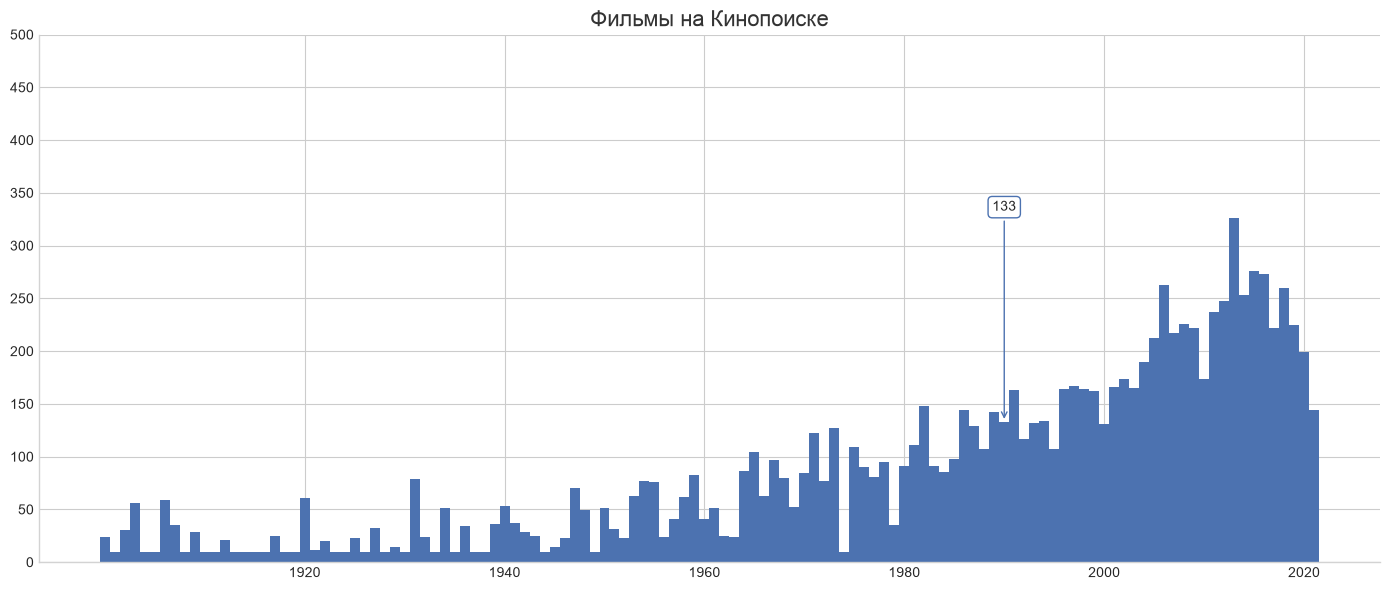

In [6]:
plt.figure(figsize=(14, 6))

# Построение столбчатой диаграммы
plt.bar(df_movies['Year'], df_movies['Count'], color='#4C72B0', width=1.0)

# Оформление
plt.title('Фильмы на Кинопоиске', fontsize=16, color='#333333')
plt.xticks(range(1920, 2021, 20))
plt.yticks(range(0, 501, 50))

# Убираем верхнюю и правую рамки для чистоты
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_color('lightgrey')
plt.gca().spines['bottom'].set_color('lightgrey')

# Добавление аннотации (пузырек с числом) как в примере
# Выберем год около 1990 для наглядности
target_year = 1990
target_count = df_movies[df_movies['Year'] == target_year]['Count'].values[0]

plt.annotate(f'{target_count}', 
             xy=(target_year, target_count), 
             xytext=(target_year, target_count + 200),
             ha='center',
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#4C72B0", lw=1),
             arrowprops=dict(arrowstyle="->", color="#4C72B0"))

plt.tight_layout()
plt.show()

## Графики сравнения оценок фильмов

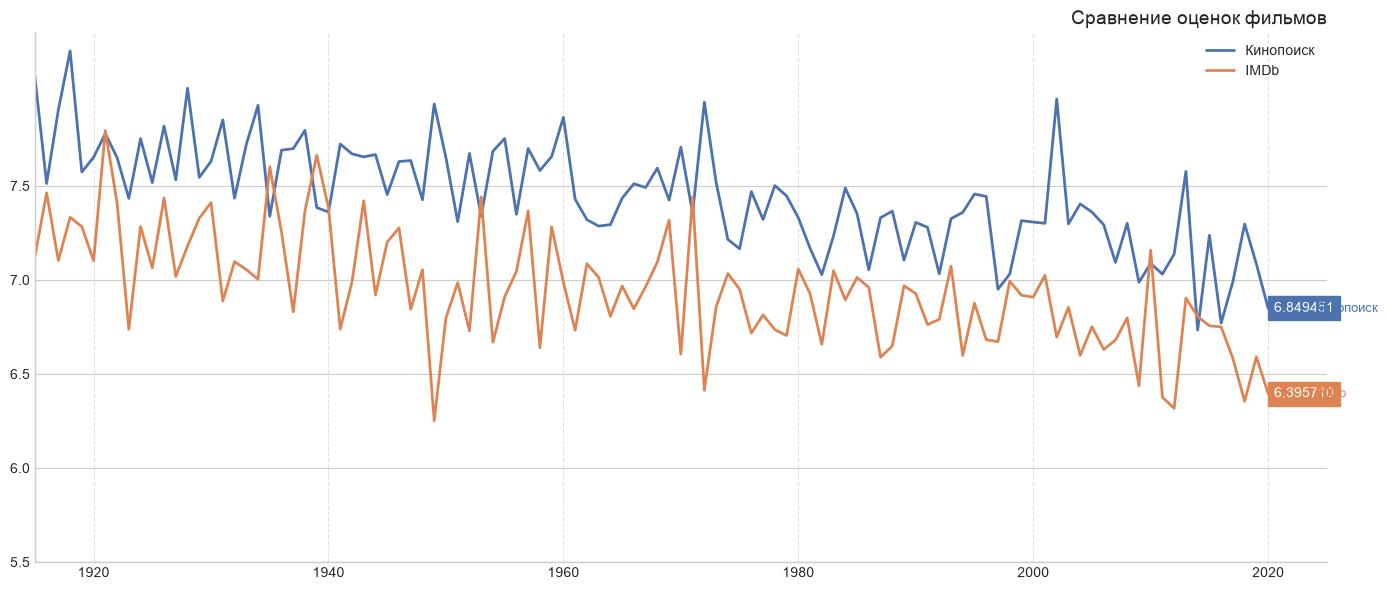

In [9]:
plt.figure(figsize=(14, 6))

# Построение линий
plt.plot(df_ratings['Year'], df_ratings['Kinopoisk'], label='Кинопоиск', color='#4C72B0', linewidth=2)
plt.plot(df_ratings['Year'], df_ratings['IMDb'], label='IMDb', color='#DD8452', linewidth=2)

# Настройки осей и сетки
plt.xticks(range(1920, 2021, 20))
plt.yticks([5.5, 6.0, 6.5, 7.0, 7.5])
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Легенда (размещаем справа сверху)
plt.legend(loc='upper right', frameon=False)

# Добавление текстовых меток в конце графиков (как на скриншоте)
last_year = df_ratings['Year'].iloc[-1]
last_kp = df_ratings['Kinopoisk'].iloc[-1]
last_imdb = df_ratings['IMDb'].iloc[-1]

plt.text(last_year + 0.5, last_kp, f'{last_kp:.6f}', color='white', backgroundcolor='#4C72B0', 
         fontsize=10, va='center')
plt.text(last_year + 0.5, last_imdb, f'{last_imdb:.6f}', color='white', backgroundcolor='#DD8452', 
         fontsize=10, va='center')

plt.text(last_year + 4, last_kp, 'Кинопоиск', color='#4C72B0', fontsize=9, va='center')
plt.text(last_year + 4, last_imdb, 'IMDb', color='#DD8452', fontsize=9, va='center')

plt.title('Сравнение оценок фильмов', fontsize=14, loc='right')
plt.xlim(1915, 2025) # Расширяем правую границу, чтобы влезли подписи

plt.tight_layout()
plt.show()

## Боксплот оценок фильмов по категориям (жанрам)

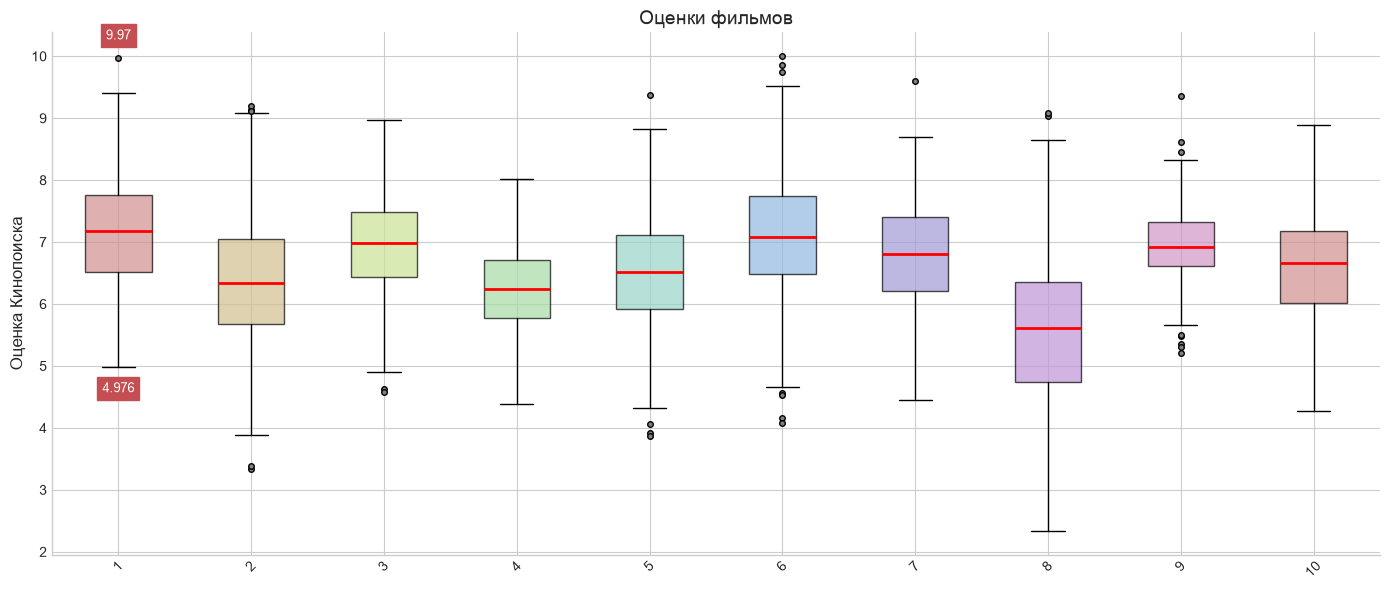

In [11]:
plt.figure(figsize=(14, 6))

# Создание боксплота
box = plt.boxplot(ratings_data, 
                  patch_artist=True, 
                  label=genres,
                  medianprops=dict(color="red", linewidth=2), # Красная линия медианы
                  flierprops=dict(marker='o', markerfacecolor='grey', markersize=4)) # Выбросы

# Задаем цветовую палитру для каждого ящика
colors = ['#d18f8f', '#d1c08f', '#cbe295', '#a6dba5', '#98d4c8', 
          '#92b8e1', '#a29bd6', '#c094d8', '#d194c6', '#d18f8f']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Настройки осей
plt.ylabel('Оценка Кинопоиска', fontsize=12)
plt.title('Оценки фильмов', fontsize=14)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Добавление аннотаций для первой категории (драма) как в примере
# Найдем максимальное и минимальное значение для 'драма'
drama_data = ratings_data[0]
max_drama = np.max(drama_data)
min_drama = np.min(drama_data)

# Верхняя аннотация
plt.text(1, max_drama + 0.3, f'{max_drama:.2f}', ha='center', 
         color='white', backgroundcolor='#c44e52', fontsize=9)

# Нижняя аннотация
plt.text(1, min_drama - 0.4, f'{min_drama:.3f}', ha='center', 
         color='white', backgroundcolor='#c44e52', fontsize=9)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()